# Stage 3 – Cross-Domain Relationship Mapping

Links the two telemetry domains and prepares the building blocks for scenario grouping (Stage 3b).

- **host** = host / process telemetry – Component 1 output (`Host.csv`, 138,945 events, 26 columns)
- **iot** = IoT network flows – Component 2 output (`IOT_Network_Flow.csv`, 59,415 flows, 22 columns)

Both files are **emulated component outputs** (generated to match the Component 1 / Component 2 interface
contracts), not real recorded traffic. **No ground-truth label (`label`, `type`, `attack_type`) is used anywhere in
this notebook** – relationships are found from the exported structure fields only: time, IP pair, ports,
protocol and process lineage.

Pipeline: load → validate → candidate pools → direct / reversed join → compare time windows (2 … 3 600 s)
→ choose W = 30 s → validate on a one-week slice → full run → save the IoT↔host links → other links
(host↔host, flow↔flow, process lineage) → save `links_all_v6v2.csv`.

**Outputs:** `window_comparison_v6v2.csv`, `window_samples_v6v2.csv`, `links_host_iot_v6v2.csv`, `links_all_v6v2.csv`
(saved next to the input files).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

print("Libraries loaded successfully")
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Libraries loaded successfully
python 3.12.4 | pandas 3.0.6 | numpy 2.5.3


## Step 1: Locate the data

- **Colab:** the cell tries to mount Google Drive and looks in `MyDrive/GNN/`; if the mount fails it looks in
  `/content` (upload the two CSV files there).
- **Local / VS Code:** start Jupyter from the project folder – the files are found in `D:/GNN`, `.` or `..`.

The files are expected under the names `Host.csv` (host) and `IOT_Network_Flow.csv` (iot);
if you use other names, change the two lists in the next cell.

Open the CSVs only in Colab / VS Code: re-saving them in Excel rewrites the `DD/MM/YYYY` timestamps
(day and month can be swapped and the seconds are dropped).

In [2]:
from pathlib import Path

HOST_NAMES = ["Host.csv"]
IOT_NAMES = ["IOT_Network_Flow.csv"]

try:                                     # only works inside Colab
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted (" + type(e).__name__ + ") - looking in local / session folders")

DIRS = ["/content/drive/MyDrive/GNN", "/content", ".", "..", "D:/GNN"]

def find(names):
    for d in DIRS:
        for n in names:
            if (Path(d) / n).is_file():
                return d, n
    return None, None

DATA_DIR, HOST_FILE = find(HOST_NAMES)
_, IOT_FILE = find(IOT_NAMES)
if HOST_FILE is None or IOT_FILE is None:
    raise FileNotFoundError(f"host / iot csv not found in {DIRS}")
print("Data folder :", Path(DATA_DIR).resolve())
print("Host file   :", HOST_FILE)
print("IoT file    :", IOT_FILE)

Drive not mounted (ModuleNotFoundError) - looking in local / session folders
Data folder : D:\GNN
Host file   : Host.csv
IoT file    : IOT_Network_Flow.csv


## Pipeline code: `relationship_mapping.py`

The functions below are used by this notebook **and** can be imported by the Stage 3b notebook, so the
matching and linking rules are defined in one place only.

| Function | What it does |
|---|---|
| `load_data` | Reads both files as text, parses timestamps strictly (`DD/MM/YYYY HH:MM:SS`), adds `row` ids |
| `network_events`, `relevant_flows` | The two candidate pools: host connect/accept events and IoT flows touching a managed host |
| `candidate_pairs`, `one_to_one` | Joins on IP pair + ports + protocol (direct and reversed), nearest timestamp, one-to-one |
| `match_iot_host` | IoT flow ↔ host event for a chosen window |
| `host_host_links` | `connect` on Host A ↔ `accept` on Host B (same tuple) |
| `flow_links` | Flows from the same device / to the same destination |
| `service_pids`, `process_links` | Process lineage: same process, parent → child, entry → child, fallback |
| `build_links_all` | Every link used by Stage 3b, one row per link |

`%%writefile` saves the cell as `relationship_mapping.py` next to the notebook; the following cells import it.

In [3]:
%%writefile relationship_mapping.py
"""Stage 3 - Cross-Domain Relationship Mapping: reusable pipeline code.

Used by the Stage 3 notebook (and imported by the Stage 3b notebook), so the
matching and linking rules are defined in one place only.

    from relationship_mapping import load_data, build_links_all
    host, iot = load_data(DATA_DIR, HOST_FILE, IOT_FILE)

Terminology
    host = host / process telemetry (one row = one host event)
    iot  = IoT network flows       (one row = one flow)
    node ids: "host:<row>" and "iot:<row>"  (row = 0-based position in the original file)

No ground-truth label column is read or used anywhere in this file.
"""

from pathlib import Path

import numpy as np
import pandas as pd

FMT = "%d/%m/%Y %H:%M:%S"
KEYS = ["src_ip", "dst_ip", "src_port", "dst_port", "protocol"]
NET_EVENTS = ["network_connect", "network_accept"]

W_MATCH = 30            # seconds, C1<->C2 correlation window (selected in the notebook, Step 4)
HOST_HOST_TOL = 5       # seconds, connect <-> accept on two hosts
FLOW_GAP = 15 * 60      # seconds, flow <-> flow continuity
ENTRY_GAP = 15 * 60     # seconds, accept -> child process
FALLBACK_GAP = 5        # seconds, accept -> child whose parent pid has no row
SERVICE_MIN_EVENTS = 30 # a pid with this many events (or PID 1) is a long-lived service


# --------------------------------------------------------------------------- loading
def load_data(data_dir, host_file, iot_file):
    """Read both files as text, parse timestamps strictly, add row ids."""
    host = pd.read_csv(Path(data_dir) / host_file, dtype=str, keep_default_na=False)
    iot = pd.read_csv(Path(data_dir) / iot_file, dtype=str, keep_default_na=False)
    host["ts"] = pd.to_datetime(host["timestamp"], format=FMT)
    iot["ts"] = pd.to_datetime(iot["timestamp"], format=FMT)
    host["row"] = np.arange(len(host))
    iot["row"] = np.arange(len(iot))
    for c in ["process_id", "parent_process_id"]:
        host[c] = host[c].astype("int64")
    return host, iot


def time_slice(df, start, end):
    return df[(df["ts"] >= pd.Timestamp(start)) & (df["ts"] < pd.Timestamp(end))]


# --------------------------------------------------------------------------- Section 1: IoT <-> host
def network_events(host):
    """Host connect/accept events in which the host itself is one endpoint."""
    net = host[host["event_type"].isin(NET_EVENTS)]
    return net[(net["src_ip"] == net["host_ip"]) | (net["dst_ip"] == net["host_ip"])]


def relevant_flows(iot, managed_ips):
    """IoT flows with a managed host at one end (the only ones that can match a host event)."""
    return iot[iot["src_ip"].isin(managed_ips) | iot["dst_ip"].isin(managed_ips)]


def candidate_pairs(rel, net):
    """All (flow, host event) pairs with the same IP pair, ports and protocol,
    in the direct form and in the reversed form (source/destination swapped)."""
    cols = KEYS + ["row", "ts", "event_type", "process_name", "host_ip", "process_id"]
    direct = rel.merge(net[cols], on=KEYS, suffixes=("", "_host"))
    direct["orient"] = "direct"
    swapped = net[cols].rename(columns={"src_ip": "dst_ip", "dst_ip": "src_ip",
                                        "src_port": "dst_port", "dst_port": "src_port"})
    reverse = rel.merge(swapped, on=KEYS, suffixes=("", "_host"))
    reverse["orient"] = "reversed"
    cand = pd.concat([direct, reverse], ignore_index=True).rename(
        columns={"row": "iot_row", "row_host": "host_row", "ts": "iot_ts", "ts_host": "host_ts"})
    cand["dt_sec"] = (cand["iot_ts"] - cand["host_ts"]).abs().dt.total_seconds()
    return cand


def one_to_one(df, a="iot_row", b="host_row", gap="dt_sec"):
    """Nearest timestamp wins; every item on either side is used at most once."""
    df = df.sort_values(gap, kind="stable")
    return df.drop_duplicates(a).drop_duplicates(b)


def match_iot_host(host, iot, managed_ips, window=W_MATCH):
    cand = candidate_pairs(relevant_flows(iot, managed_ips), network_events(host))
    return one_to_one(cand[cand["dt_sec"] <= window]).sort_values("iot_ts")


# --------------------------------------------------------------------------- Section 2: other links
def _node(prefix, rows):
    return prefix + ":" + pd.Series(rows).astype(str).to_numpy()


def _links(a_prefix, a_rows, b_prefix, b_rows, link_type, points, gap):
    return pd.DataFrame({"node_a": _node(a_prefix, a_rows), "node_b": _node(b_prefix, b_rows),
                         "link_type": link_type, "points": points, "gap_sec": np.asarray(gap, dtype=float)})


def host_host_links(host, managed_ips, tol=HOST_HOST_TOL):
    """connect on Host A  <->  accept on Host B, same tuple, within `tol` seconds."""
    net = network_events(host)
    cols = KEYS + ["row", "ts", "host_ip"]
    conn = net[(net["event_type"] == "network_connect") & (net["src_ip"] == net["host_ip"]) &
               net["dst_ip"].isin(managed_ips)][cols]
    acc = net[(net["event_type"] == "network_accept") & net["src_ip"].isin(managed_ips)][cols]
    m = conn.merge(acc, on=KEYS, suffixes=("_conn", "_acc"))
    m = m[m["host_ip_conn"] != m["host_ip_acc"]]
    m["gap"] = (m["ts_conn"] - m["ts_acc"]).abs().dt.total_seconds()
    m = m[m["gap"] <= tol].sort_values("gap", kind="stable").drop_duplicates("row_conn").drop_duplicates("row_acc")
    return _links("host", m["row_conn"], "host", m["row_acc"], "connect_accept", 3, m["gap"])


def flow_links(iot, gap=FLOW_GAP):
    """Consecutive flows that share a source and/or a destination within `gap` seconds.
    Same source AND destination is the strong link; source-only / destination-only are weak."""
    f = iot.sort_values(["ts", "row"], kind="stable")[["row", "ts", "src_ip", "dst_ip"]].reset_index(drop=True)

    def consecutive(keys):
        g = f.groupby(keys, sort=False)
        prev = g["row"].shift()
        d = (f["ts"] - g["ts"].shift()).dt.total_seconds()
        ok = prev.notna() & (d <= gap)
        return pd.DataFrame({"prev": prev[ok].astype(int), "cur": f.loc[ok, "row"], "gap": d[ok]})

    both = consecutive(["src_ip", "dst_ip"])
    seen = set(zip(both["prev"], both["cur"]))
    parts = [_links("iot", both["prev"], "iot", both["cur"], "flow_same_src_dst", 2, both["gap"])]
    for keys, ltype in ((["src_ip"], "flow_same_src"), (["dst_ip"], "flow_same_dst")):
        c = consecutive(keys)
        keep = np.array([(p, r) not in seen for p, r in zip(c["prev"], c["cur"])], dtype=bool)
        c = c[keep]
        parts.append(_links("iot", c["prev"], "iot", c["cur"], ltype, 1, c["gap"]))
    return pd.concat(parts, ignore_index=True)


def service_pids(host, min_events=SERVICE_MIN_EVENTS):
    """Long-lived services (many events) and PID 1: a shared service is NOT a shared entity."""
    counts = host["process_id"].value_counts()
    return set(counts[counts >= min_events].index) | {1}


def process_links(host, services):
    """Process-lineage links. Every link joins an earlier event to a later one."""
    h = host.sort_values(["ts", "row"], kind="stable").reset_index(drop=True)
    all_pids = set(h["process_id"])
    ps = h[h["event_type"] == "process_start"]
    acc = h[h["event_type"] == "network_accept"]
    links = []

    # (a) consecutive events of the same ephemeral (non-service) process
    eph = h[~h["process_id"].isin(services)]
    g = eph.groupby(["host_ip", "process_id"], sort=False)
    prev_row, prev_ts = g["row"].shift(), g["ts"].shift()
    d = (eph["ts"] - prev_ts).dt.total_seconds()
    ok = prev_row.notna() & (d <= ENTRY_GAP)
    links.append(_links("host", prev_row[ok].astype(int), "host", eph["row"][ok], "same_process", 2, d[ok]))

    def asof(left, right, key_left, key_right, by_left, tol):
        l = left[["row", "ts", "host_ip", key_left]].rename(columns={"row": "child_row", "ts": "child_ts", key_left: "_k"})
        r = right[["row", "ts", "host_ip", key_right]].rename(columns={"row": "prev_row", "ts": "prev_ts", key_right: "_k"})
        l = l.sort_values("child_ts", kind="stable")
        r = r.sort_values("prev_ts", kind="stable")
        by = ["host_ip", "_k"] if by_left else ["host_ip"]
        m = pd.merge_asof(l, r, left_on="child_ts", right_on="prev_ts", by=by,
                          direction="backward", tolerance=pd.Timedelta(seconds=tol))
        m = m.dropna(subset=["prev_row"])
        m["gap"] = (m["child_ts"] - m["prev_ts"]).dt.total_seconds()
        return m

    # (b) child process_start <-> latest event of its (non-service) parent
    ps_ns = ps[~ps["parent_process_id"].isin(services) & ps["parent_process_id"].isin(all_pids)]
    m = asof(ps_ns, h, "parent_process_id", "process_id", True, ENTRY_GAP)
    links.append(_links("host", m["prev_row"].astype(int), "host", m["child_row"], "parent_child", 2, m["gap"]))

    # (c) entry-to-child: child of a SERVICE process <-> nearest preceding accept handled by that service
    ps_sv = ps[ps["parent_process_id"].isin(services) & (ps["parent_process_id"] != 1)]
    m = asof(ps_sv, acc, "parent_process_id", "process_id", True, ENTRY_GAP)
    pts = np.where(m["gap"] <= 5, 3, 2)
    links.append(_links("host", m["prev_row"].astype(int), "host", m["child_row"], "entry_to_child", pts, m["gap"]))

    # (d) fallback: parent pid never appears as a row -> nearest preceding accept on the same host
    ps_or = ps[~ps["parent_process_id"].isin(all_pids)]
    m = asof(ps_or, acc, "parent_process_id", "process_id", False, FALLBACK_GAP)
    links.append(_links("host", m["prev_row"].astype(int), "host", m["child_row"], "fallback_accept", 2, m["gap"]))
    return pd.concat(links, ignore_index=True)


def build_links_all(host, iot, managed_ips, window=W_MATCH):
    """Every link used by the scenario grouping (Stage 3b): one row per link."""
    m = match_iot_host(host, iot, managed_ips, window)
    iot_host = _links("iot", m["iot_row"], "host", m["host_row"], "iot_host_match", 3, m["dt_sec"])
    parts = [iot_host, host_host_links(host, managed_ips), flow_links(iot),
             process_links(host, service_pids(host))]
    links = pd.concat(parts, ignore_index=True)
    return links.drop_duplicates(["node_a", "node_b", "link_type"]).reset_index(drop=True)

Overwriting relationship_mapping.py


In [4]:
import importlib, sys
sys.path.insert(0, ".")
import relationship_mapping as rm
importlib.reload(rm)
print("relationship_mapping imported: W_MATCH =", rm.W_MATCH, "s | host-host tolerance =", rm.HOST_HOST_TOL, "s")

relationship_mapping imported: W_MATCH = 30 s | host-host tolerance = 5 s


## Step 2: Load and validate the data

Both files are read as **text** (`dtype=str`) so no value is silently converted; only the timestamps and the
process ids are converted. `-` and blank mean *not applicable* (a `memory_event` has no IP address) and are
**not** missing data – nothing is imputed.

In [5]:
# ==========================================
# STEP 2: LOAD AND VALIDATE
# ==========================================
host, iot = rm.load_data(DATA_DIR, HOST_FILE, IOT_FILE)
managed_ips = set(host["host_ip"])           # taken from the FULL host file

print("host events :", len(host), "| columns:", host.shape[1] - 2)
print("iot flows   :", len(iot), "| columns:", iot.shape[1] - 2)
print("host time range:", host["ts"].min(), "->", host["ts"].max())
print("iot  time range:", iot["ts"].min(), "->", iot["ts"].max())
print("duplicate rows : host", host.drop(columns=["ts", "row"]).duplicated().sum(),
      "| iot", iot.drop(columns=["ts", "row"]).duplicated().sum())
print("managed hosts  :", sorted(managed_ips))
print("IoT devices    :", iot["src_ip"].nunique(), "source IPs")

print("\nhost event types:")
display(host["event_type"].value_counts().to_frame("events"))

net_mask = host["event_type"].isin(rm.NET_EVENTS)
dash = {c: int((host[c] == "-").sum()) for c in host.columns if (host[c] == "-").any()}
print("'-' (not applicable) cells in host file:", dash)
print("network events missing an IP / protocol:",
      int((host.loc[net_mask, ["src_ip", "dst_ip", "protocol"]] == "-").any(axis=1).sum()))
print("iot blank cells:", int((iot == "").sum().sum()))

host events : 138945 | columns: 26
iot flows   : 59415 | columns: 22
host time range: 2019-01-04 00:06:37 -> 2019-11-21 23:43:08
iot  time range: 2019-01-04 00:04:10 -> 2019-11-21 23:44:39


duplicate rows : host 0 | iot 0
managed hosts  : ['10.20.1.11', '10.20.1.12', '10.20.1.21', '10.20.1.22', '10.20.2.11', '10.20.2.12', '10.20.3.10', '10.20.9.5']
IoT devices    : 14 source IPs

host event types:


,events
event_type,
file_event,40555
network_accept,38583
memory_event,21212
network_connect,19395
process_start,19200


'-' (not applicable) cells in host file: {'src_ip': 80967, 'dst_ip': 80967, 'protocol': 80967, 'file_operation': 98390}
network events missing an IP / protocol: 0
iot blank cells: 0


**Result:** both files parse cleanly (138,945 host events and 59,415 flows, 4 Jan – 21 Nov 2019) with **no duplicate
rows**. The `-` placeholders are exactly where they should be: `src_ip`, `dst_ip` and `protocol` are `-` on all
80,967 non-network events (file, memory and `process_start`), and `file_operation` is `-` on the 98,390
non-file events. **All 57,978 network events carry the full IP / port / protocol tuple**, and the IoT file has no
blank cells. There are 8 managed hosts and 14 IoT source devices.

## Step 3: Candidate pools

Comparing every host event with every flow would need 85 000 × 58 000 ≈ 5 billion comparisons, so the data is
filtered **first**:

- **host pool** – connect / accept events in which the host itself is one endpoint;
- **iot pool** – flows with a managed host at one end (an IoT-to-external or IoT-to-IoT flow can never have a
  host-side event).

In [6]:
# ==========================================
# STEP 3: CANDIDATE POOLS
# ==========================================
net = rm.network_events(host)
rel = rm.relevant_flows(iot, managed_ips)

print("host network events (pool A):", len(net), "of", len(host))
print("iot flows touching a managed host (pool B):", len(rel), "of", len(iot),
      f"({len(rel) / len(iot) * 100:.1f}%)")
print("iot flows that can never match a host event:", len(iot) - len(rel))

host network events (pool A): 57978 of 138945
iot flows touching a managed host (pool B): 10462 of 59415 (17.6%)
iot flows that can never match a host event: 48953


**Result:** all 57,978 network events qualify, but only **10,462 of 59,415 flows (17.6 %)** touch a managed host – these
are the only flows that can have a host-side counterpart. The other 48,953 are IoT-to-external or IoT-to-IoT
traffic and correctly stay unmatched.

## Step 4: Join on IP pair + ports + protocol (direct and reversed)

The same connection is seen from two sides:

- **direct** – the host accepted a connection from an IoT device (source / destination agree in both files);
- **reversed** – the host opened the connection (source / destination swapped, ports swapped).

The join is done with pandas `merge` (an indexed lookup), then the time gap is added.

In [7]:
# ==========================================
# STEP 4: CANDIDATE PAIRS
# ==========================================
cand = rm.candidate_pairs(rel, net)
print("candidate pairs (same tuple, any time gap):", len(cand))
print("\norientation vs host event type:")
display(pd.crosstab(cand["orient"], cand["event_type"]))
display(cand[["iot_ts", "host_ts", "src_ip", "dst_ip", "src_port", "dst_port", "protocol",
              "orient", "event_type", "process_name", "dt_sec"]].head(5))

candidate pairs (same tuple, any time gap): 5642

orientation vs host event type:


event_type,network_accept,network_connect
orient,,
direct,4932,0
reversed,0,710


,iot_ts,host_ts,src_ip,dst_ip,src_port,dst_port,protocol,orient,event_type,process_name,dt_sec
0,2019-01-04 00:31:06,2019-01-04 00:31:07,10.30.0.1,10.20.3.10,62187,8443,TCP,direct,network_accept,nginx,1.0
1,2019-01-04 00:31:12,2019-01-04 00:31:24,10.30.0.1,10.20.3.10,22757,8443,TCP,direct,network_accept,nginx,12.0
2,2019-01-04 00:31:31,2019-01-04 00:31:37,10.30.0.1,10.20.3.10,2070,8443,TCP,direct,network_accept,nginx,6.0
3,2019-01-04 00:31:45,2019-01-04 00:31:52,10.30.0.1,10.20.3.10,53285,8443,TCP,direct,network_accept,nginx,7.0
4,2019-01-04 00:31:48,2019-01-04 00:31:56,10.30.0.1,10.20.3.10,39326,8443,TCP,direct,network_accept,nginx,8.0


**Result:** there are 5,642 candidate pairs. The direction rule holds exactly: every **direct** pair is a host
`network_accept` (4,932) and every **reversed** pair is a host `network_connect` (710) – no pair violates it.

## Step 5: Choose the time window W

The two telemetry domains do not log a connection at the same instant, so a time window is needed. A window
that is too small loses real matches; one that is too large risks false matches. Six windows are compared
(2, 5, 10, 20, 30 s and a very large 3 600 s used as a **false-match check**). For each window the matching is
one-to-one: the nearest timestamp wins.

,window_s,matched_flows,pct_of_relevant,host_rows_used,flows_with_gt1_candidate,direct,reversed
0,2,2203,21.1,2203,0,1939,264
1,5,2942,28.1,2942,0,2583,359
2,10,4241,40.5,4241,0,3712,529
3,20,5259,50.3,5259,0,4600,659
4,30,5620,53.7,5620,0,4913,707
5,3600,5620,53.7,5620,2,4913,707


time gap of the matches found at 30 s (seconds): min 0 | median 5 | p95 22 | max 28


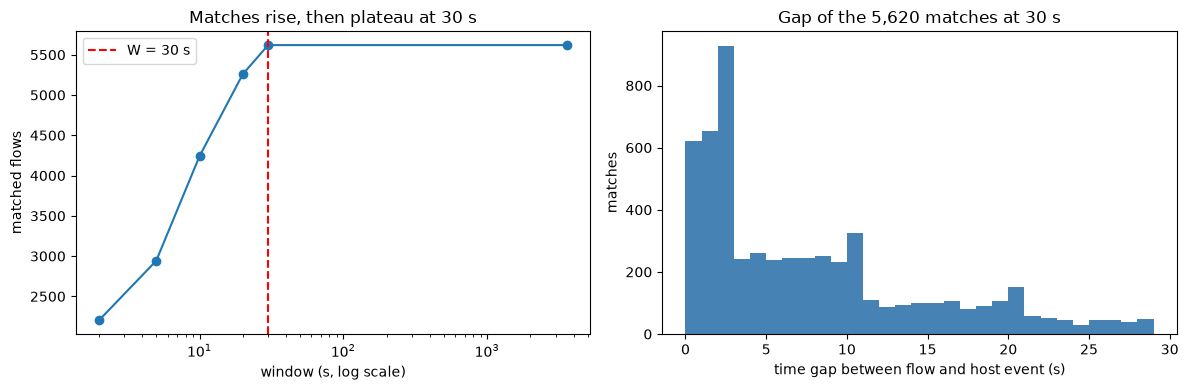

In [8]:
# ==========================================
# STEP 5: WINDOW COMPARISON
# ==========================================
WINDOWS = [2, 5, 10, 20, 30, 3600]
rows, samples = [], []
for W in WINDOWS:
    inwin = cand[cand["dt_sec"] <= W]
    per_flow = inwin.groupby("iot_row").size()
    m = rm.one_to_one(inwin)
    rows.append({"window_s": W, "matched_flows": len(m),
                 "pct_of_relevant": round(len(m) / len(rel) * 100, 1),
                 "host_rows_used": m["host_row"].nunique(),
                 "flows_with_gt1_candidate": int((per_flow > 1).sum()),
                 "direct": int((m["orient"] == "direct").sum()),
                 "reversed": int((m["orient"] == "reversed").sum())})
    samples.append(m.sort_values("iot_ts").head(10).assign(window_s=W))
window_cmp = pd.DataFrame(rows)
display(window_cmp)

best = rm.one_to_one(cand[cand["dt_sec"] <= 30])
print("time gap of the matches found at 30 s (seconds): min %.0f | median %.0f | p95 %.0f | max %.0f" %
      (best.dt_sec.min(), best.dt_sec.median(), best.dt_sec.quantile(.95), best.dt_sec.max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(window_cmp["window_s"], window_cmp["matched_flows"], marker="o")
axes[0].set_xscale("log"); axes[0].axvline(30, color="red", ls="--", label="W = 30 s")
axes[0].set_xlabel("window (s, log scale)"); axes[0].set_ylabel("matched flows"); axes[0].legend()
axes[0].set_title("Matches rise, then plateau at 30 s")
axes[1].hist(best["dt_sec"], bins=29, range=(0, 29), color="steelblue")
axes[1].set_xlabel("time gap between flow and host event (s)"); axes[1].set_ylabel("matches")
axes[1].set_title(f"Gap of the {len(best):,} matches at 30 s")
plt.tight_layout(); plt.show()

**Result:** the number of matches climbs with the window and **stops growing at 30 s** (5,620 matches, 53.7 % of the
10,462 relevant flows); widening to one hour adds nothing. A 5 s window would keep only 2,942 of them (**52 %**) and
lose 2,678 real links, because the delay between the two domains runs from 0 to 28 s (median 5 s, 95th percentile
22 s). No flow has more than one candidate at 30 s, and the one-hour check shows only 2 flows with a second
candidate (coincidental tuple reuse), so wider windows do not create false matches here.

**Decision: W = 30 s** – selected after comparing candidate windows, not guessed. (5 s can still be reported as a
"high-confidence" tier.) *The delays in this emulated data were built to span 0 – 30 s; on real data the same
comparison must be repeated.*

## Step 6: Validate on a one-week slice, then run the full dataset

Before the full run the matching is applied to **one contiguous week** (1 – 8 March 2019) – a time slice, not a
random sample of rows, because a random sample would separate the two rows of a match. Every match is
checked: same IP pair, same ports (swapped when reversed), same protocol, gap ≤ 30 s.

In [9]:
# ==========================================
# STEP 6a: ONE-WEEK SLICE
# ==========================================
W = rm.W_MATCH
h_wk = rm.time_slice(host, "2019-03-01", "2019-03-08")
i_wk = rm.time_slice(iot, "2019-03-01", "2019-03-08")
m_wk = rm.match_iot_host(h_wk, i_wk, managed_ips, W)

print("slice 2019-03-01 .. 2019-03-08: host", len(h_wk), "| iot", len(i_wk),
      "| relevant flows", len(rm.relevant_flows(i_wk, managed_ips)))
print("matches:", len(m_wk), "| direct", int((m_wk.orient == 'direct').sum()),
      "| reversed", int((m_wk.orient == 'reversed').sum()))

# every match must satisfy all the rules
ok_gap = (m_wk["dt_sec"] <= W).all()
direct = m_wk[m_wk.orient == "direct"]
ok_dir = (direct["event_type"] == "network_accept").all() and (m_wk[m_wk.orient == "reversed"]["event_type"] == "network_connect").all()
print("all gaps <= 30 s:", ok_gap, "| orientation matches event type:", ok_dir,
      "| one host event per flow:", m_wk["host_row"].is_unique and m_wk["iot_row"].is_unique)

show = ["iot_ts", "host_ts", "src_ip", "dst_ip", "src_port", "dst_port", "protocol", "orient", "event_type", "process_name", "dt_sec"]
display(m_wk[show].head(10))

slice 2019-03-01 .. 2019-03-08: host 3117 | iot 1197 | relevant flows 191
matches: 111 | direct 96 | reversed 15
all gaps <= 30 s: True | orientation matches event type: True | one host event per flow: True


,iot_ts,host_ts,src_ip,dst_ip,src_port,dst_port,protocol,orient,event_type,process_name,dt_sec
0,2019-03-01 00:20:07,2019-03-01 00:20:10,10.30.1.13,10.20.1.12,48268,443,TCP,direct,network_accept,nginx,3.0
1,2019-03-01 01:43:45,2019-03-01 01:44:04,10.30.1.13,10.20.1.11,60344,443,TCP,direct,network_accept,nginx,19.0
2,2019-03-01 04:26:03,2019-03-01 04:26:09,10.30.5.51,10.20.1.12,62542,443,TCP,direct,network_accept,nginx,6.0
3,2019-03-01 06:14:05,2019-03-01 06:14:06,10.30.2.21,10.20.3.10,64357,1883,TCP,direct,network_accept,mosquitto,1.0
4,2019-03-01 07:22:11,2019-03-01 07:22:15,10.30.1.12,10.20.1.12,10955,8443,TCP,direct,network_accept,nginx,4.0
5,2019-03-01 16:42:18,2019-03-01 16:42:20,10.30.0.1,10.20.9.5,33086,22,TCP,direct,network_accept,sshd,2.0
6,2019-03-02 02:32:20,2019-03-02 02:32:33,10.30.1.12,10.20.1.11,60809,8443,TCP,direct,network_accept,nginx,13.0
7,2019-03-02 03:13:08,2019-03-02 03:13:08,10.30.5.51,10.20.1.12,41611,8443,TCP,direct,network_accept,nginx,0.0
8,2019-03-02 04:59:58,2019-03-02 05:00:00,10.30.4.42,10.20.3.10,19893,1883,TCP,direct,network_accept,mosquitto,2.0
9,2019-03-02 05:51:02,2019-03-02 05:51:08,10.30.5.51,10.20.1.21,24716,8443,TCP,direct,network_accept,node,6.0


**Result:** the slice has 3,117 host events and 1,197 flows; 191 flows touch a managed host and **111 are matched**
(96 direct, 15 reversed). Every match shows the same IP pair, ports and protocol with a gap of 0 – 28 s, direct
matches are all `accept` events and reversed ones all `connect` events, and no host event or flow is used twice.
The rules behave correctly, so the full dataset is run next.

In [10]:
# ==========================================
# STEP 6b: FULL DATASET
# ==========================================
links_host_iot = rm.match_iot_host(host, iot, managed_ips, W)

print("relevant flows :", len(rel))
print("matches at 30 s:", len(links_host_iot),
      f"({len(links_host_iot) / len(rel) * 100:.1f}% of relevant flows)")
print("direct         :", int((links_host_iot.orient == 'direct').sum()))
print("reversed       :", int((links_host_iot.orient == 'reversed').sum()))

print("\nChecks:")
print("  matches / direct / reversed == 5620 / 4913 / 707 :",
      (len(links_host_iot), int((links_host_iot.orient == 'direct').sum()), int((links_host_iot.orient == 'reversed').sum())) == (5620, 4913, 707))
print("  every flow and every host event used at most once :", links_host_iot["iot_row"].is_unique and links_host_iot["host_row"].is_unique)
print("  flows with >1 candidate at 30 s == 0              :",
      int(window_cmp.loc[window_cmp.window_s == 30, "flows_with_gt1_candidate"].iloc[0]) == 0)
unmatched = rel[~rel["row"].isin(links_host_iot["iot_row"])]
print("\nrelevant flows with no host event:", len(unmatched), f"({len(unmatched) / len(rel) * 100:.1f}%)")
print("  by service:", unmatched["service"].value_counts().head(5).to_dict())

relevant flows : 10462
matches at 30 s: 5620 (53.7% of relevant flows)
direct         : 4913
reversed       : 707

Checks:
  matches / direct / reversed == 5620 / 4913 / 707 : True
  every flow and every host event used at most once : True
  flows with >1 candidate at 30 s == 0              : True

relevant flows with no host event: 4842 (46.3%)
  by service: {'HTTPS': 2446, 'HTTP': 884, 'MQTT': 607, 'Modbus/TCP': 297, 'MQTTS': 285}


**Result:** the full run gives **5,620 matches (53.7 % of the 10,462 relevant flows)** – 4,913 direct and 707 reversed –
and every check passes. The remaining 4,842 relevant flows (46.3 %) have no host event: Component 1 does not observe every
flow, and part of these flows are follow-up flows that the data contains for small scenarios and that have no host counterpart
by design. They stay in the data as ordinary unmatched flows and are not forced into a link.

## Step 7: Save the IoT ↔ host results

These three files are the evidence for the panel: the window comparison, ten example matches per window, and the
final link table with real IPs, ports and timestamps (readable, not just row numbers).

In [11]:
# ==========================================
# STEP 7: SAVE SECTION-1 OUTPUTS
# ==========================================
OUT = Path(DATA_DIR)
window_cmp.to_csv(OUT / "window_comparison_v6v2.csv", index=False)

show = ["window_s", "iot_ts", "host_ts", "src_ip", "dst_ip", "src_port", "dst_port",
        "protocol", "orient", "event_type", "process_name", "dt_sec"]
pd.concat(samples)[show].to_csv(OUT / "window_samples_v6v2.csv", index=False)

out_cols = ["iot_row", "host_row", "orient", "dt_sec", "iot_ts", "host_ts", "src_ip", "dst_ip",
            "src_port", "dst_port", "protocol", "event_type", "process_name", "host_ip"]
links_host_iot[out_cols].reset_index(drop=True).to_csv(OUT / "links_host_iot_v6v2.csv", index=False)

for f in ["window_comparison_v6v2.csv", "window_samples_v6v2.csv", "links_host_iot_v6v2.csv"]:
    print("saved", OUT / f)
display(links_host_iot[out_cols].head(5))

saved D:\GNN\window_comparison_v6v2.csv
saved D:\GNN\window_samples_v6v2.csv
saved D:\GNN\links_host_iot_v6v2.csv


,iot_row,host_row,orient,dt_sec,iot_ts,host_ts,src_ip,dst_ip,src_port,dst_port,protocol,event_type,process_name,host_ip
0,3,6,direct,1.0,2019-01-04 00:31:06,2019-01-04 00:31:07,10.30.0.1,10.20.3.10,62187,8443,TCP,network_accept,nginx,10.20.3.10
1,4,8,direct,12.0,2019-01-04 00:31:12,2019-01-04 00:31:24,10.30.0.1,10.20.3.10,22757,8443,TCP,network_accept,nginx,10.20.3.10
2,9,9,direct,6.0,2019-01-04 00:31:31,2019-01-04 00:31:37,10.30.0.1,10.20.3.10,2070,8443,TCP,network_accept,nginx,10.20.3.10
4932,11,10,reversed,8.0,2019-01-04 00:31:41,2019-01-04 00:31:49,10.30.0.1,10.20.3.10,49945,8443,TCP,network_connect,nginx,10.20.3.10
3,12,11,direct,7.0,2019-01-04 00:31:45,2019-01-04 00:31:52,10.30.0.1,10.20.3.10,53285,8443,TCP,network_accept,nginx,10.20.3.10


## Step 8: Other links

An IoT↔host link is only one kind of relationship. Scenario grouping (Stage 3b) also needs the links **inside**
each domain. Every link has a type and a number of **points** (how strong the evidence is):

| Link type | Joins | Rule | Points |
|---|---|---|---|
| `iot_host_match` | IoT flow ↔ host event | Steps 5–6, W = 30 s | 3 |
| `connect_accept` | `connect` on Host A ↔ `accept` on Host B | same tuple, ≤ 5 s | 3 |
| `flow_same_src_dst` | consecutive flows | same source device **and** destination, ≤ 15 min | 2 |
| `flow_same_src`, `flow_same_dst` | consecutive flows | same source only / same destination only, ≤ 15 min | 1 (weak) |
| `same_process` | consecutive events | same **ephemeral** process, ≤ 15 min | 2 |
| `parent_child` | child `process_start` ↔ latest event of its parent | parent is not a service, ≤ 15 min | 2 |
| `entry_to_child` | child of a **service** process ↔ nearest earlier `accept` handled by that service | ≤ 15 min | 3 if ≤ 5 s, else 2 |
| `fallback_accept` | child whose parent pid never appears as a row ↔ nearest earlier `accept` on the same host | ≤ 5 s | 2 |

A **service process** is PID 1 or any process with 30 or more events in the whole dataset (web-server workers,
listeners, daemons). Many unrelated connections pass through the same service, so a shared service is **not** a
shared entity – this is why child processes are linked to the specific `accept` that led to them.

In [12]:
# ==========================================
# STEP 8a: SERVICE PROCESSES
# ==========================================
services = rm.service_pids(host)
sv = (host[host["process_id"].isin(services)]
      .groupby(["process_id", "process_name"]).size().sort_values(ascending=False))
print(len(services), "service pids carry", f"{host['process_id'].isin(services).mean() * 100:.1f}%", "of all host events")
display(sv.head(8).to_frame("events"))

51

 service pids carry 47.1% of all host events


,,events
process_id,process_name,
2011,nginx,4784
2010,nginx,4712
2005,nginx,4651
2004,nginx,4568
1,systemd,3984
2023,python3,2868
2022,python3,2830
2041,nginx,2451


**Result:** 51 service processes (PID 1 and 50 processes with ≥ 30 events: `nginx` workers, `python3` listeners and
other daemons) carry **47.1 %** of all host events. If a shared service counted as a shared entity, thousands of
unrelated events would be merged into one scenario – so these are excluded as linking entities.

In [13]:
# ==========================================
# STEP 8b: BUILD ALL LINKS
# ==========================================
import time
t0 = time.time()
links_all = rm.build_links_all(host, iot, managed_ips, W)
print("built in %.1f s" % (time.time() - t0))

summary = (links_all.groupby("link_type")
           .agg(links=("points", "size"), points=("points", lambda s: "/".join(map(str, sorted(s.unique())))),
                median_gap_s=("gap_sec", "median"), p95_gap_s=("gap_sec", lambda s: s.quantile(.95)))
           .sort_values("links", ascending=False).round(1))
display(summary)
print("total links:", len(links_all))
links_all.to_csv(OUT / "links_all_v6v2.csv", index=False)
print("saved", OUT / "links_all_v6v2.csv")

built in 0.9 s


,links,points,median_gap_s,p95_gap_s
link_type,,,,
same_process,47488,2,7.0,148.0
entry_to_child,11877,2/3,1.0,3.0
connect_accept,8171,3,0.0,1.0
flow_same_src_dst,7411,2,3.0,22.0
flow_same_src,5892,1,431.0,856.0
iot_host_match,5620,3,5.0,22.0
parent_child,3286,2,2.0,83.0
flow_same_dst,1023,1,453.0,853.9
fallback_accept,695,2,1.0,2.0


total links: 91463
saved D:\GNN\links_all_v6v2.csv


**Result:** **91,463 links** in nine types, built in about a second. The most frequent are `same_process` (47,488, consecutive
events of one short-lived process) and `entry_to_child` (11,877, a service `accept` and the process it started); the
strongest cross-domain evidence is `iot_host_match` (5,620) and `connect_accept` (8,171 host-to-host connections seen from both
hosts). Flow links add 7,411 strong (`flow_same_src_dst`) and 6,915 weak ones (`flow_same_src` 5,892 + `flow_same_dst` 1,023);
the weak links are only candidates – whether they are strong enough to join events is decided in Stage 3b. Process lineage
adds 63,346 links in total (`same_process` 47,488, `entry_to_child` 11,877, `parent_child` 3,286, `fallback_accept` 695).
97.7 % of the `entry_to_child` links have a gap of 5 s or less (maximum 598 s).

## Step 9: Look at one real example of every link type

A link table with row numbers is hard to check, so one link of each type is shown with the actual events on both
sides. Read each line to confirm that the two events really belong together.

In [14]:
# ==========================================
# STEP 9: ONE READABLE EXAMPLE PER LINK TYPE
# ==========================================
def describe(node):
    kind, row = node.split(":")
    r = host.iloc[int(row)] if kind == "host" else iot.iloc[int(row)]
    if kind == "host":
        tup = f" {r.src_ip}:{r.src_port}->{r.dst_ip}:{r.dst_port} {r.protocol}" if r.event_type in rm.NET_EVENTS else ""
        return f"{r.timestamp} | {r.host_ip} | {r.process_name}[{r.process_id}] | {r.event_type}{tup}"
    return f"{r.timestamp} | IoT flow {r.src_ip}:{r.src_port}->{r.dst_ip}:{r.dst_port} {r.protocol} {r.service}"

ex = links_all.groupby("link_type").sample(1, random_state=7).sort_values("link_type")
for _, r in ex.iterrows():
    print(f"[{r.link_type}  +{r.points}  gap {r.gap_sec:.0f}s]")
    print("   A:", describe(r.node_a))
    print("   B:", describe(r.node_b))

[connect_accept  +3  gap 0s]
   A: 12/08/2019 16:06:38 | 10.20.1.22 | python3[2022] | network_connect 10.20.1.22:52329->10.20.2.11:3306 TCP
   B: 12/08/2019 16:06:38 | 10.20.2.11 | mysqld[2025] | network_accept 10.20.1.22:52329->10.20.2.11:3306 TCP
[entry_to_child  +2  gap 368s]
   A: 25/08/2019 23:29:00 | 10.20.1.12 | nginx[2010] | network_accept 10.30.2.24:20988->10.20.1.12:443 TCP
   B: 25/08/2019 23:35:08 | 10.20.1.12 | bash[4148] | process_start
[fallback_accept  +2  gap 1s]
   A: 11/07/2019 18:25:10 | 10.20.2.11 | sshd[2026] | network_accept 203.0.113.11:19652->10.20.2.11:22 TCP
   B: 11/07/2019 18:25:11 | 10.20.2.11 | bash[6345] | process_start
[flow_same_dst  +1  gap 155s]
   A: 29/06/2019 07:54:57 | IoT flow 10.30.2.24:58048->203.0.113.4:5683 UDP CoAP
   B: 29/06/2019 07:57:32 | IoT flow 10.30.3.32:31799->203.0.113.4:53 TCP DNS
[flow_same_src  +1  gap 252s]
   A: 17/09/2019 22:52:51 | IoT flow 10.30.1.11:20399->203.0.113.8:8443 TCP HTTPS
   B: 17/09/2019 22:57:03 | IoT flow 10

**Result:** each example reads as one real relationship – an IoT flow and the host `accept` with the same address
and ports a few seconds later, a `connect` on one host and the matching `accept` on the next, a service `accept`
followed by the process it started, and consecutive flows from the same device. The weak links (`flow_same_src`,
`flow_same_dst`) join flows that only share one end, which is why they are kept as weak candidates. The sampled
`entry_to_child` example has a long gap (368 s, 2 points instead of 3); only 2.3 % of these links are longer than 60 s.

## Step 10: Final checks

In [15]:
# ==========================================
# STEP 10: SANITY CHECKS
# ==========================================
n_host, n_iot = len(host), len(iot)

def valid(col):
    kind = col.str.split(":").str[0]
    row = col.str.split(":").str[1].astype(int)
    return ((kind == "host") & (row < n_host)) | ((kind == "iot") & (row < n_iot))

print("all node ids point to a real row   :", bool(valid(links_all.node_a).all() and valid(links_all.node_b).all()))
print("no link joins a node to itself     :", bool((links_all.node_a != links_all.node_b).all()))
print("no duplicate links                 :", not links_all.duplicated(["node_a", "node_b", "link_type"]).any())
print("host-host links inside 5 s         :", bool((links_all[links_all.link_type == "connect_accept"].gap_sec <= 5).all()))
print("iot-host links inside 30 s         :", bool((links_all[links_all.link_type == "iot_host_match"].gap_sec <= 30).all()))
print("process / flow links inside 15 min :", bool((links_all[~links_all.link_type.isin(["connect_accept", "iot_host_match", "fallback_accept"])].gap_sec <= 900).all()))
print("label columns used by this notebook: none (label, type, attack_type, predicted_class never read)")

all node ids point to a real row   : True
no link joins a node to itself     : True
no duplicate links                 : True
host-host links inside 5 s         : True
iot-host links inside 30 s         : True
process / flow links inside 15 min : True
label columns used by this notebook: none (label, type, attack_type, predicted_class never read)


**Result:** all node ids resolve to a real row, no link is a self-link or a duplicate, and every link respects its
time rule. Stage 3 is complete: `links_all_v6v2.csv` (91,463 links) is the input to Stage 3b.

## Limitations

| Limitation | How the notebook reduces it | What remains |
|---|---|---|
| Emulated data, not real recorded traffic | Uses the Component 1 / 2 output format and tests the rules on one week before the full run | The pipeline is proven here; the same steps must be rerun on real data |
| W = 30 s fits this data | Six windows compared, large window used as a false-match check | The delay in this data was built to span 0 – 30 s; the window must be re-chosen on real data |
| Some relevant flows have no host event | Not forced into a link | Component 1 does not see every flow, so some flows stay unmatched by design |
| Weak flow links (+1) are only candidates | Kept separate from the strong links, with their own points | Whether they join scenarios is decided in Stage 3b (threshold sweep) |
| Process lineage is incomplete | `entry_to_child` and `fallback_accept` links bridge missing parent rows | Some chains (accept → shell) may still split; Stage 3b measures how many before any data change |
| Service threshold (≥ 30 events) is data-driven | Services are found from the data; their events are not used as shared entities | The cut-off is a design choice and should be stated in the report |
| Links are not scenarios | – | Grouping events into scenarios is Stage 3b |